In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Environment Ready!")

Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
Environment Ready!


In [3]:
df = pd.read_csv("/telco_churn_cleaned.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "MultipleLines",
    "PaperlessBilling",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "gender"
]

features = numeric_features + categorical_features

model_df = df[features + ["Churn"]].copy()

model_df["Churn"] = model_df["Churn"].map({
    "Yes": 1,
    "No": 0
})

print("Model Table Shape:", model_df.shape)
print("Missing TotalCharges:", model_df["TotalCharges"].isnull().sum())

Model Table Shape: (7043, 19)
Missing TotalCharges: 11


In [5]:
from sklearn.model_selection import train_test_split

X = model_df[features]
y = model_df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("Training Churn Rate:", round(y_train.mean() * 100, 2), "%")
print("Testing Churn Rate:", round(y_test.mean() * 100, 2), "%")

Training Shape: (5634, 18)
Testing Shape: (1409, 18)
Training Churn Rate: 26.54 %
Testing Churn Rate: 26.54 %


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_score

In [7]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [8]:
# Baseline Model
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Main Model
gradient_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression
lr_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Gradient Boosting
gb_scores = cross_val_score(
    gradient_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Logistic Regression CV AUC:", lr_scores)
print("Logistic Regression Mean AUC:", round(lr_scores.mean(), 4))

print("\nGradient Boosting CV AUC:", gb_scores)
print("Gradient Boosting Mean AUC:", round(gb_scores.mean(), 4))

Logistic Regression CV AUC: [0.84789071 0.82511956 0.84202575 0.86298329 0.85305715]
Logistic Regression Mean AUC: 0.8462

Gradient Boosting CV AUC: [0.84031312 0.83038066 0.84453412 0.86057187 0.86244151]
Gradient Boosting Mean AUC: 0.8476


In [10]:
# Train Logistic Regression
logistic_pipeline.fit(X_train, y_train)

# Train Gradient Boosting
gradient_pipeline.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [11]:
# Predictions
lr_predictions = logistic_pipeline.predict(X_test)
gb_predictions = gradient_pipeline.predict(X_test)

# Churn probabilities
lr_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
gb_probabilities = gradient_pipeline.predict_proba(X_test)[:, 1]

print("Test predictions generated successfully!")

Test predictions generated successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

def evaluate_model(name, y_true, predictions, probabilities):

    print(f"\n{'='*45}")
    print(name)
    print(f"{'='*45}")

    print("Accuracy:", round(accuracy_score(y_true, predictions), 4))
    print("Precision:", round(precision_score(y_true, predictions), 4))
    print("Recall:", round(recall_score(y_true, predictions), 4))
    print("F1 Score:", round(f1_score(y_true, predictions), 4))
    print("ROC-AUC:", round(roc_auc_score(y_true, probabilities), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, predictions))

    print("\nClassification Report:")
    print(classification_report(y_true, predictions))

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_predictions,
    gb_probabilities
)


Logistic Regression
Accuracy: 0.8048
Precision: 0.6562
Recall: 0.5561
F1 Score: 0.602
ROC-AUC: 0.8419

Confusion Matrix:
[[926 109]
 [166 208]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409


Gradient Boosting
Accuracy: 0.8062
Precision: 0.6735
Recall: 0.5241
F1 Score: 0.5895
ROC-AUC: 0.8434

Confusion Matrix:
[[940  95]
 [178 196]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



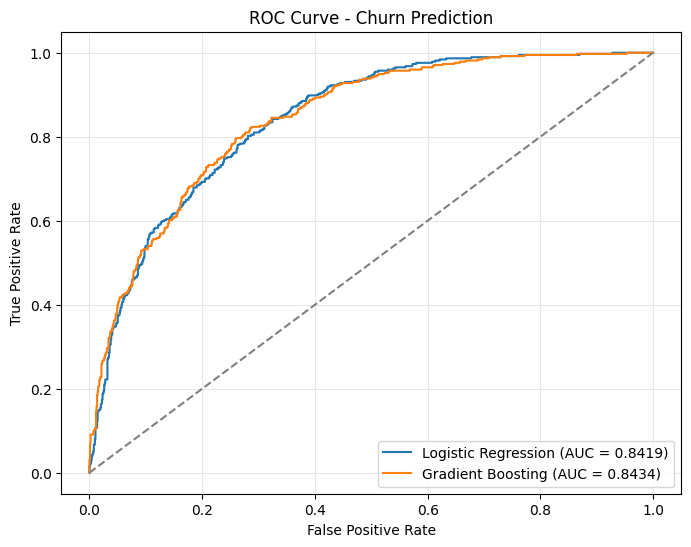

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ROC Curve
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_probabilities)

plt.figure(figsize=(8, 6))
plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, lr_probabilities):.4f})")
plt.plot(gb_fpr, gb_tpr, label=f"Gradient Boosting (AUC = {roc_auc_score(y_test, gb_probabilities):.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
def calculate_top_decile_lift(y_true, probabilities, model_name):
    results = pd.DataFrame({
        "actual": np.asarray(y_true),
        "probability": probabilities
    })

    results = results.sort_values(
        "probability", ascending=False
    )

    top_10_percent = results.head(int(np.ceil(len(results) * 0.10)))

    overall_churn_rate = results["actual"].mean()
    top_decile_churn_rate = top_10_percent["actual"].mean()

    lift = top_decile_churn_rate / overall_churn_rate
    churners_captured = (
        top_10_percent["actual"].sum() / results["actual"].sum()
    )

    print(f"\n{model_name}")
    print("Customers in top 10%:", len(top_10_percent))
    print("Top-decile churn rate:", round(top_decile_churn_rate * 100, 2), "%")
    print("Overall churn rate:", round(overall_churn_rate * 100, 2), "%")
    print("Top-decile lift:", round(lift, 2), "x")
    print("Share of all churners captured:", round(churners_captured * 100, 2), "%")

calculate_top_decile_lift(
    y_test, lr_probabilities, "Logistic Regression"
)

calculate_top_decile_lift(
    y_test, gb_probabilities, "Gradient Boosting"
)


Logistic Regression
Customers in top 10%: 141
Top-decile churn rate: 74.47 %
Overall churn rate: 26.54 %
Top-decile lift: 2.81 x
Share of all churners captured: 28.07 %

Gradient Boosting
Customers in top 10%: 141
Top-decile churn rate: 77.3 %
Overall churn rate: 26.54 %
Top-decile lift: 2.91 x
Share of all churners captured: 29.14 %


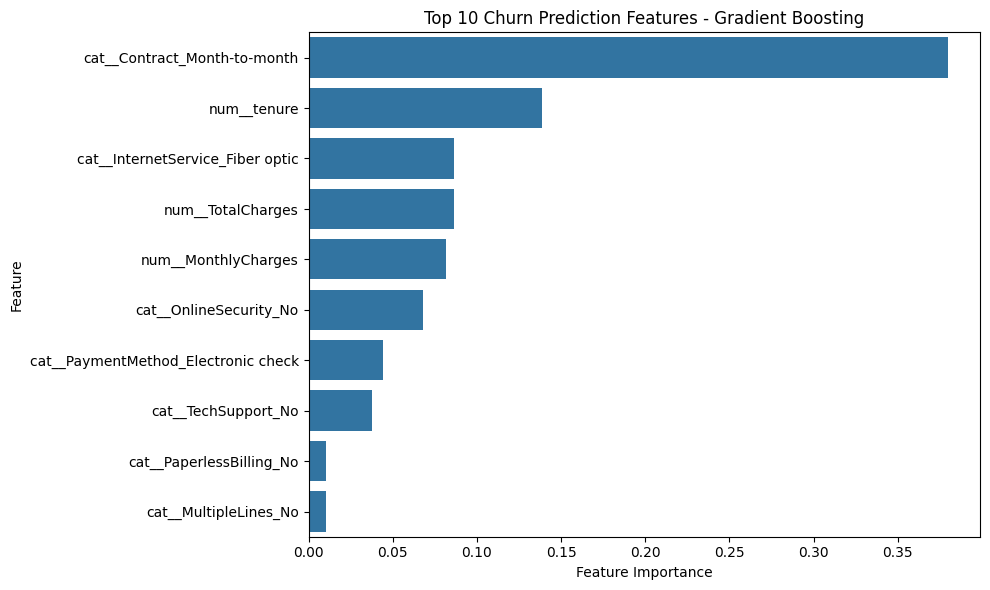

,Feature,Importance
3,cat__Contract_Month-to-month,0.379910
0,num__tenure,0.138642
11,cat__InternetService_Fiber optic,0.086523
2,num__TotalCharges,0.086156
1,num__MonthlyCharges,0.081947
13,cat__OnlineSecurity_No,0.068142
8,cat__PaymentMethod_Electronic check,0.044430
16,cat__TechSupport_No,0.037823
34,cat__PaperlessBilling_No,0.010662
31,cat__MultipleLines_No,0.010302


In [15]:
# Extract feature names after preprocessing
feature_names = gradient_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = gradient_pipeline.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top_10_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Churn Prediction Features - Gradient Boosting")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(top_10_features)

In [16]:
import os
from sklearn.base import clone

# Keep customer IDs separate from model features
final_model = clone(gradient_pipeline)
final_model.fit(X, y)

# Predict churn probabilities for all customers
all_probabilities = final_model.predict_proba(X)[:, 1]

# Create customer risk list
winback_list = pd.DataFrame({
    "customerID": df["customerID"],
    "ChurnRiskProbability": all_probabilities,
    "MonthlyCharges": df["MonthlyCharges"]
})

# Highest risk first
winback_list = winback_list.sort_values(
    "ChurnRiskProbability",
    ascending=False
).head(100)

# Save CSV
os.makedirs("/content/data/processed", exist_ok=True)

output_path = "/content/data/processed/winback_list.csv"
winback_list.to_csv(output_path, index=False)

print("Top 100 winback list created successfully!")
print("Potential monthly charges:", round(winback_list["MonthlyCharges"].sum(), 2))

display(winback_list.head(10))

Top 100 winback list created successfully!
Potential monthly charges: 8270.2


,customerID,ChurnRiskProbability,MonthlyCharges
7032,6894-LFHLY,0.937549,75.75
6623,9248-OJYKK,0.936229,76.45
2208,7216-EWTRS,0.936170,100.80
6482,5419-JPRRN,0.930336,101.45
2464,2609-IAICY,0.930227,77.15
1704,0107-YHINA,0.927357,99.75
3209,8149-RSOUN,0.925464,93.85
2577,4910-GMJOT,0.908538,94.60
6866,0295-PPHDO,0.908216,95.45
3380,5178-LMXOP,0.907197,95.10


In [18]:
# Use the already trained Gradient Boosting model.
# It was trained only on X_train, not X_test.

active_test_customers = df.loc[
    X_test.index,
    ["customerID", "MonthlyCharges", "Churn"]
].copy()

active_test_customers["ChurnRiskProbability"] = gb_probabilities

# Keep only customers who have not churned
active_test_customers = active_test_customers[
    active_test_customers["Churn"] == "No"
].copy()

# Rank by predicted churn probability
winback_list_test = active_test_customers.sort_values(
    "ChurnRiskProbability",
    ascending=False
).head(100)

# Export without actual churn labels
winback_list_test = winback_list_test[
    ["customerID", "ChurnRiskProbability", "MonthlyCharges"]
]

winback_list_test.to_csv(
    "/content/winback_list_test.csv",
    index=False
)

print("Active customer winback list created!")
print("Customers:", len(winback_list_test))
print(
    "Combined monthly charges: $",
    round(winback_list_test["MonthlyCharges"].sum(), 2)
)

display(winback_list_test.head(10))

Active customer winback list created!
Customers: 100
Combined monthly charges: $ 7782.0


,customerID,ChurnRiskProbability,MonthlyCharges
3536,2254-DLXRI,0.880389,79.15
2927,5542-TBBWB,0.856466,69.90
5905,1628-BIZYP,0.845196,85.00
4039,8161-QYMTT,0.844369,94.10
2519,4927-WWOOZ,0.842875,91.45
2036,8775-ERLNB,0.839725,74.30
85,4445-ZJNMU,0.832185,99.30
3346,2545-EBUPK,0.825703,84.05
935,6630-UJZMY,0.822427,83.25
2280,2754-SDJRD,0.819613,100.15


In [19]:
from google.colab import files

files.download("/content/winback_list_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>